# 71 · Multimodality: why averaging two good actions gives a bad one

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.toy_envs import AroundObstacleEnv, collect_around
from vlacourse import show_video

torch.manual_seed(0)

def fit_mse(eps, epochs=300):
    X = torch.tensor(np.concatenate([e["obs"] for e in eps])); Y = torch.tensor(np.concatenate([e["act"] for e in eps]))
    net = nn.Sequential(nn.Linear(4, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 2))
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(256):
            loss = ((net(X[idx]) - Y[idx]) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return net

def rollout(env, act_fn, seed, frames=None):
    o = env.reset(seed=seed); path, done = [env.pos()], False
    while not done:
        o, _, done, info = env.step(act_fn(o)); path.append(env.pos())
        if frames is not None:
            frames.append(env.render())
    return np.array(path), info

def draw_scene(ax):
    ax.add_patch(plt.Circle((0, 0), 0.18, color="tab:red", alpha=0.5)); ax.add_patch(plt.Circle((0, 0.55), 0.05, color="tab:green", alpha=0.5))
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.65, 0.65); ax.set_aspect("equal")

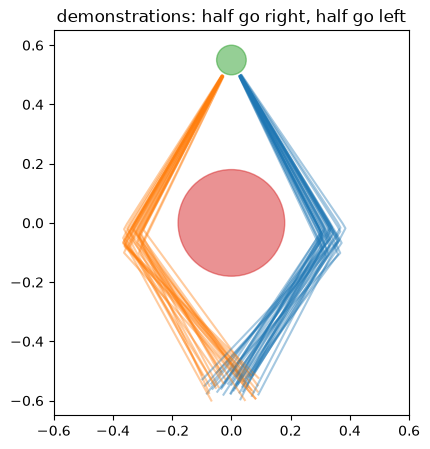

In [2]:
eps = collect_around(200, seed=0)
fig, ax = plt.subplots(figsize=(5, 5)); draw_scene(ax)
for e in eps[:60]:
    ax.plot(e["obs"][:, 0], e["obs"][:, 1], color="tab:blue" if e["side"] > 0 else "tab:orange", alpha=0.4)
ax.set_title("demonstrations: half go right, half go left"); plt.show()

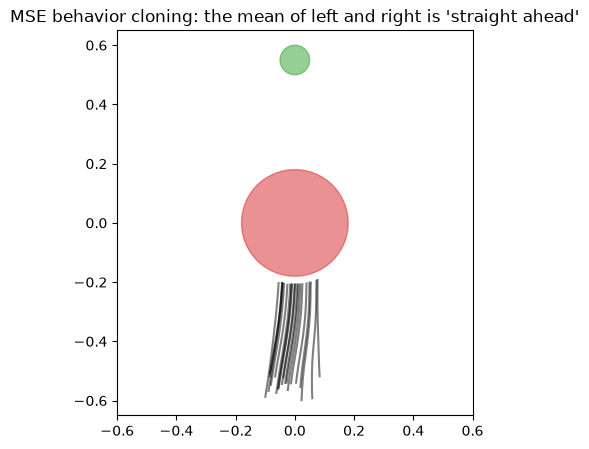

MSE policy: success 0.00, collided 1.00


In [3]:
net = fit_mse(eps)
env = AroundObstacleEnv(); frames = []
fig, ax = plt.subplots(figsize=(5, 5)); draw_scene(ax)
results = []
for s in range(20):
    path, info = rollout(env, lambda o: net(torch.tensor(o)).detach().numpy(), 1000 + s, frames if s == 0 else None)
    ax.plot(path[:, 0], path[:, 1], "k", alpha=0.5); results.append(info)
ax.set_title("MSE behavior cloning: the mean of left and right is 'straight ahead'"); plt.show()
print(f"MSE policy: success {np.mean([r['success'] for r in results]):.2f}, collided {np.mean([r['collided'] for r in results]):.2f}")
show_video(frames, fps=30, title="MSE BC")

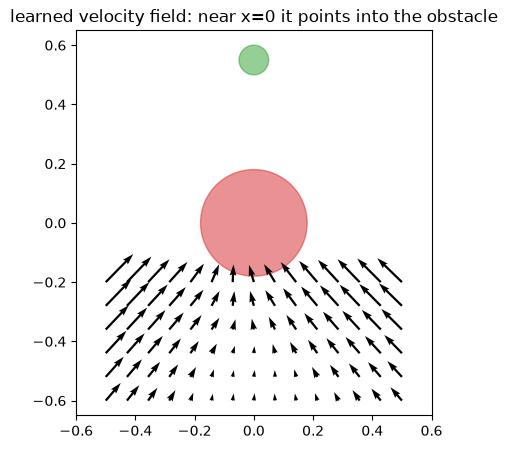

In [4]:
grid = np.stack(np.meshgrid(np.linspace(-0.5, 0.5, 15), np.linspace(-0.6, -0.2, 6)), -1).reshape(-1, 2)
obs = torch.tensor(np.c_[grid, np.zeros_like(grid)], dtype=torch.float32)
with torch.no_grad():
    v = net(obs).numpy()
fig, ax = plt.subplots(figsize=(6, 5)); draw_scene(ax)
ax.quiver(grid[:, 0], grid[:, 1], v[:, 0], v[:, 1], color="k")
ax.set_title("learned velocity field: near x=0 it points into the obstacle"); plt.show()